# 02 · Limpeza, filtragem e criação de variáveis

Transforma os dados brutos na **base analítica**: sinistros **com vítima** em **rodovias e vias
urbanas** de **Campinas e Guarulhos**, **2022–2025**. Tudo em **Polars**.

| Etapa | O que faz |
|---|---|
| 1 | Funil de seleção (cada filtro registra quantas linhas restam) |
| 2 | Variáveis temporais: ano, mês, dia da semana, fim de semana, hora e período |
| 3 | Gravidade do sinistro a partir de `qtd_gravidade_*` |
| 4 | Flags de veículos/modos (moto, bicicleta, pedestre, automóvel, caminhão, ônibus, pesado) |
| 5 | Flags de tipo de sinistro (atropelamento, capotamento, tombamento, colisões…) |
| 6 | Nome padronizado de rodovias/vias e km; validação de coordenadas |
| 7 | Pessoas e veículos vinculados aos sinistros selecionados |
| 8 | Checagens de consistência e gravação em `data/processed/` |

**Correções em relação à versão anterior do projeto:** as flags de moto/caminhão/bicicleta eram
procuradas em colunas `tp_veiculo_*` que não existem no InfoSiga (ficavam sempre falsas); a
gravidade procurava `gravidade_fatal` (o nome real é `qtd_gravidade_fatal`); e capotamento não
existe em `tp_sinistro_primario` — ele vem da flag `tp_sinistro_capotamento`.

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
from src import config, limpeza, viz

viz.tema()
pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(45)
sin_b = pl.read_parquet(config.DATA_INTERIM / "sinistros_bruto.parquet")
pes_b = pl.read_parquet(config.DATA_INTERIM / "pessoas_bruto.parquet")
vei_b = pl.read_parquet(config.DATA_INTERIM / "veiculos_bruto.parquet")

## 1–6. Funil de seleção e variáveis derivadas
A função `limpeza.preparar_sinistros` (em `src/limpeza.py`) executa, em ordem:
remoção de `id_sinistro` duplicado → municípios → **somente `SINISTRO FATAL` e
`SINISTRO NAO FATAL`** → tipo de via (`ESTRADAS E RODOVIAS` → RODOVIA, `VIAS URBANAS` → VIA URBANA;
`NAO DISPONIVEL` sai) → anos 2022–2025. Depois cria as variáveis.

In [2]:
sin, funil = limpeza.preparar_sinistros(sin_b)
print(f"\nBase analítica: {sin.height:,} sinistros")

  Bruto (2022–2026, todos os municípios)                 902,074


  Sem id_sinistro duplicado                              902,074


  Campinas + Guarulhos                                    46,511


  Somente sinistros com vítima (exclui NOTIFICACAO)       29,475
  Tipo de via = rodovia ou via urbana                     29,404


  Período 2022–2025 com data válida                       25,858



Base analítica: 25,858 sinistros


In [3]:
print("Sinistros por município × tipo de via × ano:")
tab = (sin.group_by("municipio", "grupo_via", "ano").len()
          .pivot(on="ano", index=["municipio", "grupo_via"], values="len", sort_columns=True)
          .sort("municipio", "grupo_via"))
viz.salvar_tab(tab.to_pandas(), "02_base_municipio_via_ano")
tab

Sinistros por município × tipo de via × ano:


  ✔ tabela salva: reports/tables/02_base_municipio_via_ano.csv


municipio,grupo_via,2022,2023,2024,2025
str,str,u64,u64,u64,u64
"""CAMPINAS""","""RODOVIA""",1026,891,865,587
"""CAMPINAS""","""VIA URBANA""",2256,2543,2448,2003
"""GUARULHOS""","""RODOVIA""",1059,1173,1245,711
"""GUARULHOS""","""VIA URBANA""",2297,2379,2373,2002


### Gravidade do sinistro
Regra (hierárquica): **FATAL** se `qtd_gravidade_fatal > 0` ou registro `SINISTRO FATAL`;
senão **GRAVE** se há ferido grave; senão **LEVE** se há ferido leve; senão
**SEM VÍTIMA / N.D.** (vítimas com lesão "não disponível" ou só ilesos informados).

In [4]:
grav = (sin.group_by("municipio", "grupo_via", "gravidade").len()
           .pivot(on="gravidade", index=["municipio", "grupo_via"], values="len")
           .select("municipio", "grupo_via", *config.ORDEM_GRAVIDADE).sort("municipio", "grupo_via"))
grav

municipio,grupo_via,SEM VÍTIMA / N.D.,LEVE,GRAVE,FATAL
str,str,u64,u64,u64,u64
"""CAMPINAS""","""RODOVIA""",357,2266,452,294
"""CAMPINAS""","""VIA URBANA""",1615,6514,847,274
"""GUARULHOS""","""RODOVIA""",1460,2262,247,219
"""GUARULHOS""","""VIA URBANA""",976,6975,771,329


### Flags de veículos e tipos de sinistro
Cada flag indica se o sinistro **envolveu** aquele modo/tipo (um sinistro pode ter várias).

In [5]:
flags = list(config.FLAGS_VEICULO) + list(config.FLAGS_TIPO)
cont_flags = (sin.group_by("municipio", "grupo_via")
                 .agg([pl.col(f).sum() for f in flags]).sort("municipio", "grupo_via"))
viz.salvar_tab(cont_flags.to_pandas(), "02_contagem_flags")
cont_flags.transpose(include_header=True, header_name="flag",
                     column_names=[f"{m[:3]}-{v[:3]}" for m, v in cont_flags.select("municipio", "grupo_via").rows()])

  ✔ tabela salva: reports/tables/02_contagem_flags.csv


flag,CAM-ROD,CAM-VIA,GUA-ROD,GUA-VIA
str,str,str,str,str
"""municipio""","""CAMPINAS""","""CAMPINAS""","""GUARULHOS""","""GUARULHOS"""
"""grupo_via""","""RODOVIA""","""VIA URBANA""","""RODOVIA""","""VIA URBANA"""
"""envolve_moto""","""1941""","""5262""","""2712""","""5809"""
"""envolve_bicicleta""","""53""","""185""","""69""","""222"""
"""envolve_pedestre""","""137""","""677""","""205""","""1134"""
"""envolve_automovel""","""2074""","""6108""","""2688""","""5874"""
"""envolve_caminhao""","""383""","""239""","""543""","""422"""
"""envolve_onibus""","""104""","""581""","""122""","""479"""
"""envolve_pesado""","""473""","""808""","""650""","""886"""


In [6]:
print("Distribuição do tipo detalhado (exclusivo):")
sin.group_by("tipo_detalhado").len().sort("len", descending=True)

Distribuição do tipo detalhado (exclusivo):


tipo_detalhado,len
str,u64
"""Colisão lateral""",5788
"""Colisão frontal""",4804
"""Colisão transversal""",4024
"""OUTROS / N.D.""",3232
"""Tombamento""",2916
"""Atropelamento""",2464
"""Choque""",1677
"""Capotamento""",616
"""Engavetamento""",337


### Nomes de vias e coordenadas
Rodovias: o código (`SP 330`, `BR 116`…) é padronizado como `SP-330`; somente rodovias de nome
inequívoco recebem o nome entre parênteses. Vias urbanas: acentos removidos, `AVENIDA` → `AV.`,
e algumas grafias duplicadas óbvias unificadas (lista em `limpeza.ALIAS_URBANO`).

In [7]:
print("Rodovias encontradas:")
display(sin.filter(pl.col("grupo_via") == "RODOVIA").group_by("municipio", "via_nome").len()
           .sort("municipio", "len", descending=[False, True]))
print("Coordenadas válidas (dentro da caixa do município):")
sin.group_by("municipio", "grupo_via").agg((pl.col("coord_valida").mean() * 100).round(1)
                                           .alias("% coord válida")).sort("municipio", "grupo_via")

Rodovias encontradas:


municipio,via_nome,len
str,str,u64
"""CAMPINAS""","""SP-330 (Anhanguera)""",815
"""CAMPINAS""","""SP-075 (Santos Dumont)""",610
"""CAMPINAS""","""SP-065 (D. Pedro I)""",574
"""CAMPINAS""","""SP-348 (Bandeirantes)""",358
"""CAMPINAS""","""SP-101""",198
"""CAMPINAS""","""SP-340""",179
"""CAMPINAS""","""SP-083""",142
"""CAMPINAS""","""SP-332""",135
"""CAMPINAS""","""SP-073""",103


Coordenadas válidas (dentro da caixa do município):


municipio,grupo_via,% coord válida
str,str,f64
"""CAMPINAS""","""RODOVIA""",98.6
"""CAMPINAS""","""VIA URBANA""",97.7
"""GUARULHOS""","""RODOVIA""",99.0
"""GUARULHOS""","""VIA URBANA""",96.9


## 7. Pessoas e veículos dos sinistros selecionados
`categoria_vitima` combina o tipo de vítima e o veículo em que estava:
PEDESTRE · MOTOCICLISTA · CICLISTA · OCUPANTE AUTOMÓVEL · OCUPANTE VEÍC. PESADO · OUTROS / N.D.

In [8]:
pes = limpeza.preparar_pessoas(pes_b, sin)
vei = limpeza.preparar_veiculos(vei_b, sin)
funil += [{"etapa": "Pessoas vinculadas aos sinistros selecionados", "linhas": pes.height},
          {"etapa": "Veículos vinculados aos sinistros selecionados", "linhas": vei.height}]
print(f"Pessoas: {pes.height:,} | Veículos: {vei.height:,}")
display(pes.group_by("categoria_vitima").len().sort("len", descending=True))
display(pes.group_by("gravidade_lesao").len().sort("len", descending=True))
vei.group_by("tipo_veiculo").len().sort("len", descending=True)

Pessoas: 50,909 | Veículos: 45,930


categoria_vitima,len
str,u64
"""OCUPANTE AUTOMÓVEL""",20730
"""MOTOCICLISTA""",17746
"""OUTROS / N.D.""",6751
"""OCUPANTE VEÍC. PESADO""",2821
"""PEDESTRE""",2805
"""CICLISTA""",56


gravidade_lesao,len
str,u64
"""ILESO""",22077
"""LEVE""",22015
"""NAO DISPONIVEL""",3176
"""GRAVE""",2473
"""FATAL""",1168


tipo_veiculo,len
str,u64
"""AUTOMOVEL""",20563
"""MOTOCICLETA""",16602
"""NAO DISPONIVEL""",4105
"""CAMINHAO""",1747
"""ONIBUS""",1330
"""OUTROS""",1054
"""BICICLETA""",529


## 8. Checagens de consistência
- Nenhuma flag de veículo importante pode estar zerada (era o erro da versão anterior).
- A soma por município × via × ano tem de bater com a contagem direta no CSV bruto.

In [9]:
for f in ["envolve_moto", "envolve_bicicleta", "envolve_pedestre", "envolve_pesado", "tp_capotamento"]:
    n = sin[f].sum()
    assert n > 0, f"flag {f} zerada"
    print(f"  {f:<20} {n:>6,} sinistros")

direto = (sin_b.filter(pl.col("municipio").is_in(config.MUNICIPIOS)
                       & pl.col("tipo_registro").is_in(config.REGISTROS_COM_VITIMA)
                       & pl.col("tipo_via").is_in(list(config.GRUPO_VIA))
                       & pl.col("ano_sinistro").is_in([str(a) for a in config.ANOS]))
                .unique("id_sinistro").height)
assert direto == sin.height, (direto, sin.height)
print(f"\n✔ Contagem direta no bruto = {direto:,} = base analítica")

  envolve_moto         15,724 sinistros
  envolve_bicicleta       529 sinistros
  envolve_pedestre      2,153 sinistros
  envolve_pesado        2,817 sinistros
  tp_capotamento          620 sinistros

✔ Contagem direta no bruto = 25,858 = base analítica


## 9. Funil e gravação

  ✔ tabela salva: reports/tables/funil_selecao.csv


,etapa,linhas
0,"Bruto (2022–2026, todos os municípios)",902074
1,Sem id_sinistro duplicado,902074
2,Campinas + Guarulhos,46511
3,Somente sinistros com vítima (exclui NOTIFICACAO),29475
4,Tipo de via = rodovia ou via urbana,29404
5,Período 2022–2025 com data válida,25858
6,Pessoas vinculadas aos sinistros selecionados,50909
7,Veículos vinculados aos sinistros selecionados,45930


  ✔ figura salva: reports/figures/02_funil_selecao.png


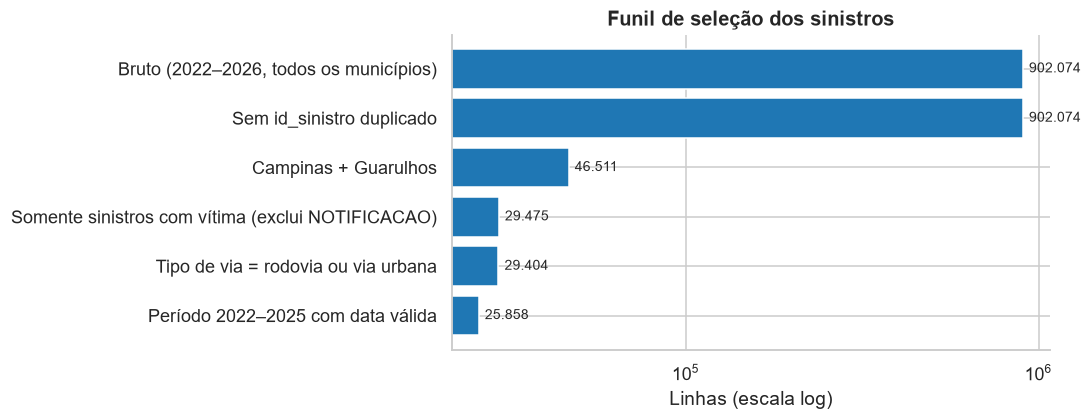

In [10]:
funil_df = pd.DataFrame(funil)
viz.salvar_tab(funil_df, "funil_selecao")
display(funil_df)

f = funil_df.iloc[:6]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(f.etapa[::-1], f.linhas[::-1], color="#1f77b4")
ax.bar_label(ax.containers[0], labels=[f"{v:,}".replace(",", ".") for v in f.linhas[::-1]],
             padding=4, fontsize=9)
ax.set_xscale("log"); ax.set(title="Funil de seleção dos sinistros", xlabel="Linhas (escala log)")
plt.tight_layout(); viz.salvar_fig(fig, "02_funil_selecao"); plt.show()

In [11]:
sin.write_parquet(config.DATA_PROCESSED / "sinistros.parquet")
pes.write_parquet(config.DATA_PROCESSED / "pessoas.parquet")
vei.write_parquet(config.DATA_PROCESSED / "veiculos.parquet")
print(f"✔ Base final: {sin.height:,} sinistros | {pes.height:,} pessoas | {vei.height:,} veículos")

✔ Base final: 25,858 sinistros | 50,909 pessoas | 45,930 veículos
